In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [8]:
print("Dataset shape:", df.shape)
print("Column names:", df.columns)
print("Total records:", len(df))
print(df.isnull().sum())

Dataset shape: (303, 14)
Column names: Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')
Total records: 303
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [10]:
df = df.drop_duplicates()

print("Duplicates removed.")
print("New dataset shape:", df.shape)

Duplicates removed.
New dataset shape: (303, 14)


In [11]:
df["target"] = (df["target"] > 0).astype(int)

print(df["target"].value_counts())

target
0    164
1    139
Name: count, dtype: int64


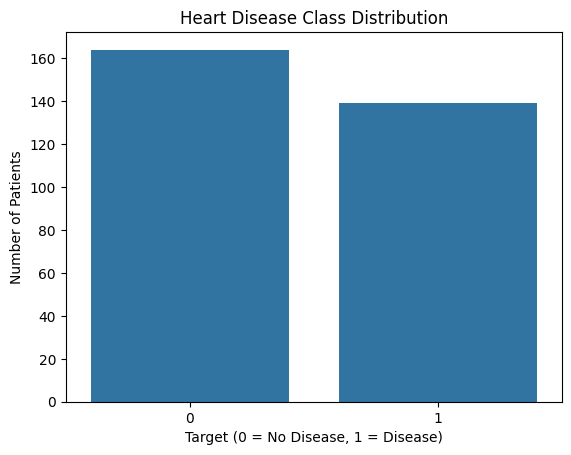

In [12]:
sns.countplot(data=df, x="target")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

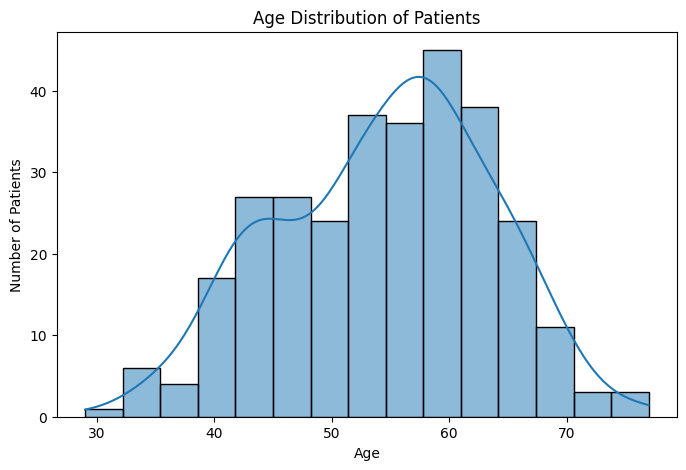

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df["age"], bins=15, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

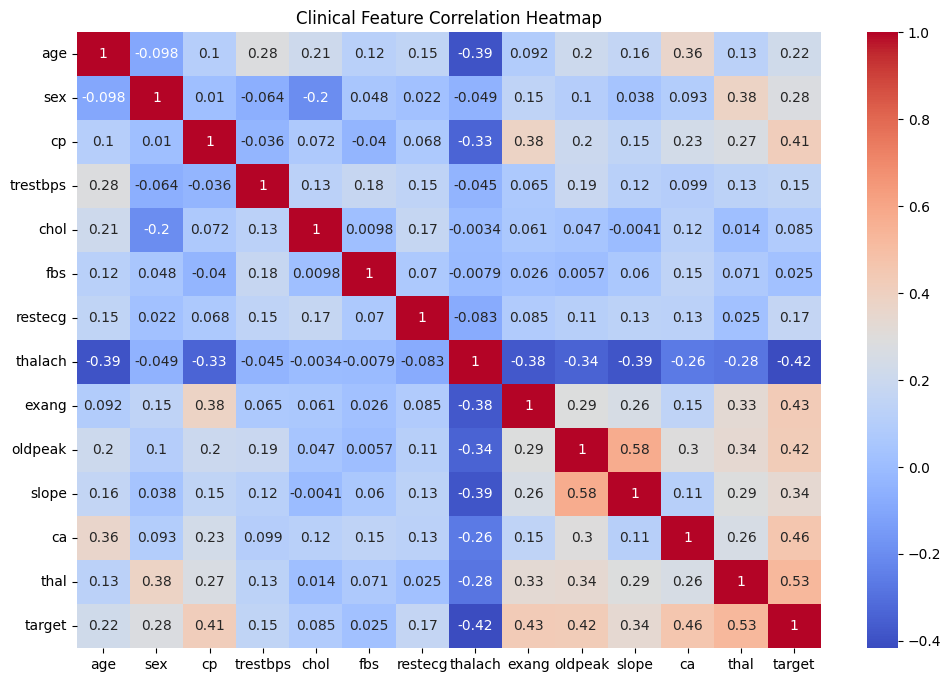

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Clinical Feature Correlation Heatmap")

plt.show()

In [15]:
X = df.drop("target", axis=1)

y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 242
Testing records: 61


In [16]:
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numerical_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [17]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

In [18]:
print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Training Random Forest...")

random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Training Logistic Regression...
Training Random Forest...
Both models trained successfully!


In [19]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", name)
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print(results_df)


 Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61


 Random Forest
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.885246    0.83871  0.928571  0.881356
1        Random Forest  0.885246    0.83871  0.928571  0.881356


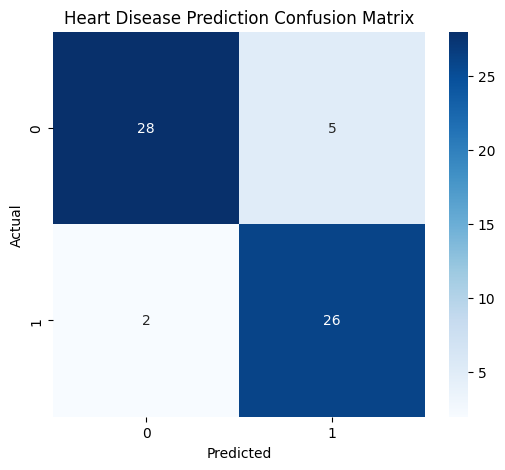

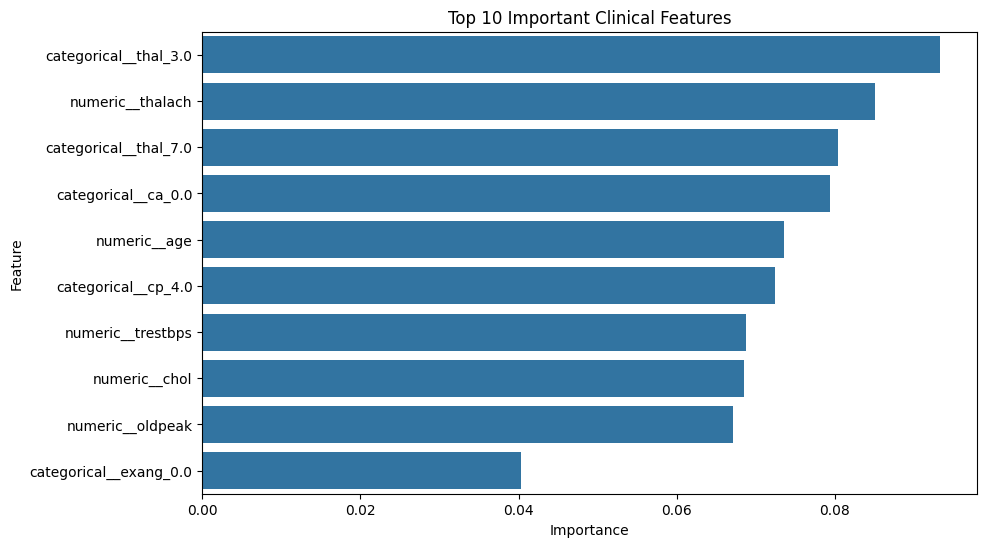

In [32]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, final_predictions),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Heart Disease Prediction Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Clinical Features")

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

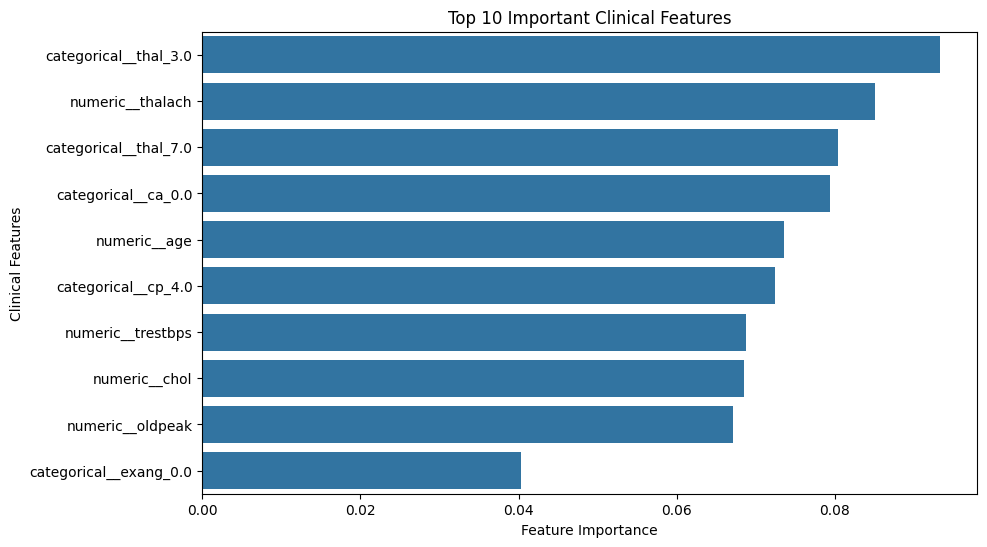

In [21]:
rf_classifier = random_forest_model.named_steps["classifier"]

feature_names = (
    random_forest_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

importance = rf_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Clinical Features")
plt.xlabel("Feature Importance")
plt.ylabel("Clinical Features")

plt.show()

In [22]:
patient = pd.DataFrame([{
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 130,
    "chol": 240,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.2,
    "slope": 2,
    "ca": 0,
    "thal": 2
}])

prediction = logistic_model.predict(patient)

probability = logistic_model.predict_proba(patient)[0][1]

print("Predicted class:", prediction[0])

print("Model probability:", round(probability * 100, 2), "%")

if prediction[0] == 1:
    print("Model classification: Heart disease present")
else:
    print("Model classification: No heart disease detected")

Predicted class: 0
Model probability: 41.78 %
Model classification: No heart disease detected


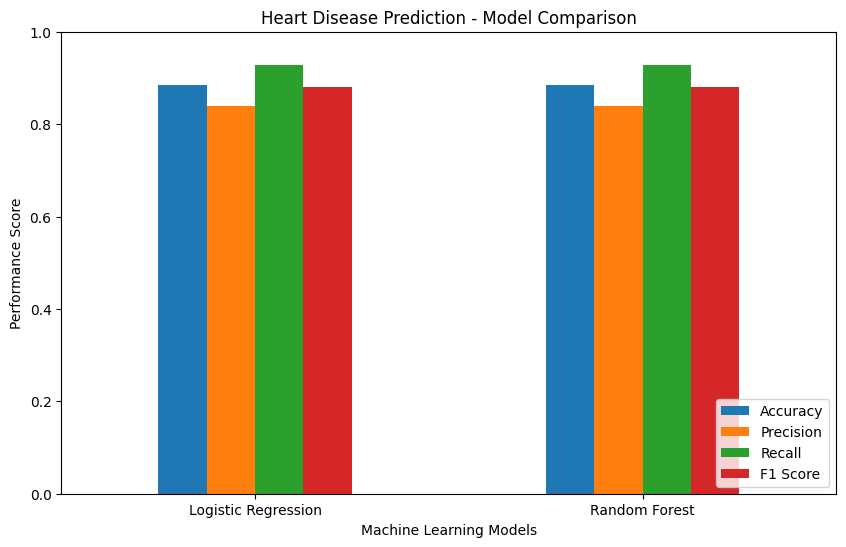

In [23]:
# Compare model performance

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Heart Disease Prediction - Model Comparison")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.legend(loc="lower right")
plt.show()

In [24]:
# Predict the test dataset

final_predictions = random_forest_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Value": y_test.values,
    "Predicted Value": final_predictions
})

print(comparison.head(10))

   Actual Value  Predicted Value
0             0                0
1             0                1
2             0                0
3             0                0
4             0                0
5             0                0
6             0                0
7             0                0
8             1                1
9             0                0


In [25]:
def predict_heart_disease(patient_data):

    patient_df = pd.DataFrame([patient_data])

    prediction = random_forest_model.predict(patient_df)

    probability = random_forest_model.predict_proba(patient_df)[0][1]

    print("Heart Disease Prediction")

    if prediction[0] == 1:
        print("Result: Heart disease class predicted")
    else:
        print("Result: No heart disease class predicted")

    print("Model probability:", round(probability * 100, 2), "%")


# Example patient

new_patient = {
    "age": 55,
    "sex": 1,
    "cp": 2,
    "trestbps": 130,
    "chol": 240,
    "fbs": 0,
    "restecg": 1,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 1.2,
    "slope": 2,
    "ca": 0,
    "thal": 2
}

predict_heart_disease(new_patient)

Heart Disease Prediction
Result: No heart disease class predicted
Model probability: 40.0 %


In [26]:
import joblib

# Save the trained model

joblib.dump(
    random_forest_model,
    "heart_disease_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [28]:
from google.colab import files

files.download("heart_disease_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
loaded_model = joblib.load("heart_disease_model.pkl")

In [33]:
files.download("confusion_matrix.png")
files.download("feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Patient input fields

age_input = widgets.IntSlider(
    value=55, min=20, max=100, description="Age:"
)

chol_input = widgets.IntSlider(
    value=240, min=100, max=600, description="Chol:"
)

bp_input = widgets.IntSlider(
    value=130, min=80, max=250, description="BP:"
)

heart_rate_input = widgets.IntSlider(
    value=150, min=60, max=220, description="Max HR:"
)

button = widgets.Button(
    description="Predict",
    button_style="success"
)

output = widgets.Output()

def on_predict_click(b):

    patient = {
        "age": age_input.value,
        "sex": 1,
        "cp": 2,
        "trestbps": bp_input.value,
        "chol": chol_input.value,
        "fbs": 0,
        "restecg": 1,
        "thalach": heart_rate_input.value,
        "exang": 0,
        "oldpeak": 1.2,
        "slope": 2,
        "ca": 0,
        "thal": 2
    }

    with output:
        clear_output()

        predict_heart_disease(patient)

button.on_click(on_predict_click)

display(
    age_input,
    chol_input,
    bp_input,
    heart_rate_input,
    button,
    output
)

IntSlider(value=55, description='Age:', min=20)

IntSlider(value=240, description='Chol:', max=600, min=100)

IntSlider(value=130, description='BP:', max=250, min=80)

IntSlider(value=150, description='Max HR:', max=220, min=60)

Button(button_style='success', description='Predict', style=ButtonStyle())

Output()